# 05 · Evaluación de hipótesis

**Propósito.** Evaluar con estadística las tres hipótesis del proyecto (README, sección 6), como pide la consigna de
la PreEntrega 3: no solo significancia, sino **magnitud, incertidumbre, robustez y relevancia** para el fondo. Cierra
pedidos de la devolución de la PreEntrega 2: H1 tenía apoyo débil, faltaban tests formales, validación temporal con
un segundo relevamiento y completar H3 con tren, Metrobus y espacios verdes.

| Hipótesis | Sección |
|---|---|
| H1: hay avisos publicados claramente por debajo de su precio esperado | 2 |
| H2: la sub-zona da una referencia de precio más precisa que el barrio | 3 |
| H3: la ubicación (transporte y entorno) explica parte del precio dentro del barrio | 4 |

**Reglas comunes.**
- **Población:** el dataset limpio (27.578 avisos), con los resultados de la etapa 6 (`precio_esperado.tsv`).
- **Unidad:** misma dirección y superficie. Los avisos de una misma unidad no son independientes, así que los
  intervalos salen de remuestrear unidades (bootstrap) y los errores estándar se agrupan por unidad, salvo que se
  diga otra cosa.
- **Tests formales:** para cada uno se explicita H0, H1, estadístico, p-valor y decisión al 5%, en una tabla resumen
  por hipótesis. Con muchas pruebas a la vez se corrige con Holm.
- **Con casi 27.000 avisos, casi cualquier diferencia da p < 0,05.** Por eso la conclusión se apoya en la magnitud y
  su intervalo; el test es el respaldo formal, no el argumento.
- Las celdas de interpretación las completa el grupo.

## 1. Configuración e ingesta

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import inferencia, modelo
from src.configuracion import cargar_config
from src.eda import AZUL, AZUL_OSCURO, GRIS, ROJO

CFG = cargar_config()
SEMILLA = CFG["analisis"]["semilla"]
limpio = pd.read_csv(RAIZ / CFG["rutas"]["limpio"], sep="\t", low_memory=False)
etapa6 = pd.read_csv(RAIZ / CFG["rutas"]["precio_esperado"], sep="\t")
seguimiento = pd.read_csv(RAIZ / "data/processed/seguimiento_avisos.csv")
assert (limpio["id_aviso"].values == etapa6["id_aviso"].values).all()
assert (limpio["id_aviso"].values == seguimiento["id_aviso"].values).all()

df = etapa6.copy()
df["unidad_cv"] = modelo.grupo_de_unidad(limpio).values
df["residuo"] = np.log1p(df["brecha"])                 # log(publicado / esperado), modelo oficial
df["residuo_gbm"] = np.log1p(df["brecha_otro_modelo"])
df["tercil_barrio"] = pd.qcut(df.groupby("barrio")["precio_m2_usd"].transform("median"), 3,
                              labels=["barrios baratos", "medios", "caros"])
print(f"Avisos: {len(df):,} | unidades: {df['unidad_cv'].nunique():,} | modelo oficial: {df['modelo_oficial'].iloc[0]}")

Avisos: 27,578 | unidades: 24,552 | modelo oficial: lineal_ampliado


## 2. H1: hay avisos publicados claramente por debajo de su precio esperado

> Dentro de una zona hay avisos publicados claramente por debajo del precio esperado para sus características, más
> allá del margen normal de negociación. Son **señales a investigar, no oportunidades confirmadas**.

Se evalúa por dos caminos:
- **H1a (la distribución):** ¿hay más avisos muy por debajo del precio esperado de lo que daría el error normal del
  modelo? Si la cola de abajo no es más pesada, la brecha prioriza qué revisar pero no prueba precios atípicos.
- **H1b (la validación con el segundo relevamiento):** si la brecha capta precios realmente bajos, esos avisos
  tendrían que salir del portal más rápido que el resto. Es una prueba externa al modelo, que la PreEntrega 2 no
  tenía.

### 2.1 H1a: ¿la cola de abajo es más pesada de lo esperable?

En log, una brecha de −25% (log 0,75 = −0,288) es simétrica a una de +33%. Si el error fuera simétrico, habría tantos
avisos por debajo de −25% como por encima de +33%. Se compara además con una normal de la misma dispersión robusta
(MAD), que no se deja arrastrar por las colas. Como H1 afirma que la cola de abajo es **más** pesada, el test de
colas es unilateral: rechazar H0 solo apoya a H1 si la masa de abajo es mayor.

In [2]:
pruebas_h1 = []
umbral_log = np.log(1 + CFG["analisis"]["umbral"])     # −0,288
abajo = df["residuo"] < umbral_log
arriba = df["residuo"] > -umbral_log
# H1 dice que la cola de abajo es MÁS pesada: la prueba es unilateral. Binomial exacta sobre los avisos de las dos
# colas (la versión unilateral del χ² de bondad de ajuste a 50/50)
binomial = stats.binomtest(int(abajo.sum()), int(abajo.sum() + arriba.sum()), 0.5, alternative="greater")
pruebas_h1.append(inferencia.fila_prueba(
    "Binomial exacta unilateral (colas)", "P(brecha < −25%) ≤ P(brecha > +33%)",
    "la cola de abajo tiene más masa", "proporción en la cola de abajo", binomial.statistic, binomial.pvalue))

dif, inf, sup = inferencia.bootstrap_estadistico(abajo.astype(float) - arriba.astype(float), df["unidad_cv"],
                                                 b=500, semilla=SEMILLA)
centro = df["residuo"].median()
mad = stats.median_abs_deviation(df["residuo"], scale="normal")
masa_normal = stats.norm.cdf(umbral_log, centro, mad)
exceso, inf_e, sup_e = inferencia.bootstrap_estadistico(abajo.astype(float) - masa_normal, df["unidad_cv"], b=500,
                                                        semilla=SEMILLA)
print(f"Por debajo de −25%: {abajo.sum():,} ({100 * abajo.mean():.1f}%) | por encima de +33%: {arriba.sum():,} "
      f"({100 * arriba.mean():.1f}%)")
print(f"Diferencia de masa (abajo − arriba): {100 * dif:+.2f} pp (IC {100 * inf:+.2f} a {100 * sup:+.2f})")
print(f"Masa de abajo frente a una normal con la misma dispersión robusta (σ = {mad:.3f}): observada "
      f"{100 * abajo.mean():.2f}%, esperada {100 * masa_normal:.2f}%, exceso {100 * exceso:+.2f} pp "
      f"(IC {100 * inf_e:+.2f} a {100 * sup_e:+.2f})")

Por debajo de −25%: 1,800 (6.5%) | por encima de +33%: 2,130 (7.7%)
Diferencia de masa (abajo − arriba): -1.20 pp (IC -1.67 a -0.73)
Masa de abajo frente a una normal con la misma dispersión robusta (σ = 0.187): observada 6.53%, esperada 6.31%, exceso +0.21 pp (IC -0.08 a +0.51)


In [3]:
z = (df["residuo"] - centro) / mad
ks = stats.ks_1samp(z, stats.norm.cdf)
pruebas_h1.append(inferencia.fila_prueba(
    "Kolmogorov-Smirnov contra la normal", "el residuo estandarizado es normal", "no es normal", "D",
    ks.statistic, ks.pvalue))
muestra = z.sample(5000, random_state=SEMILLA)              # shapiro admite hasta 5.000 datos
sh = stats.shapiro(muestra)
pruebas_h1.append(inferencia.fila_prueba(
    "Shapiro-Wilk (muestra de 5.000)", "el residuo es normal", "no es normal", "W", sh.statistic, sh.pvalue))
print(f"KS: D = {ks.statistic:.3f} (p = {ks.pvalue:.1e}) | Shapiro: W = {sh.statistic:.3f} (p = {sh.pvalue:.1e})")
print("Con este tamaño de muestra, rechazar la normalidad es casi seguro: lo que importa es dónde y cuánto se aparta.")

KS: D = 0.018 (p = 1.6e-08) | Shapiro: W = 0.971 (p = 8.8e-31)
Con este tamaño de muestra, rechazar la normalidad es casi seguro: lo que importa es dónde y cuánto se aparta.


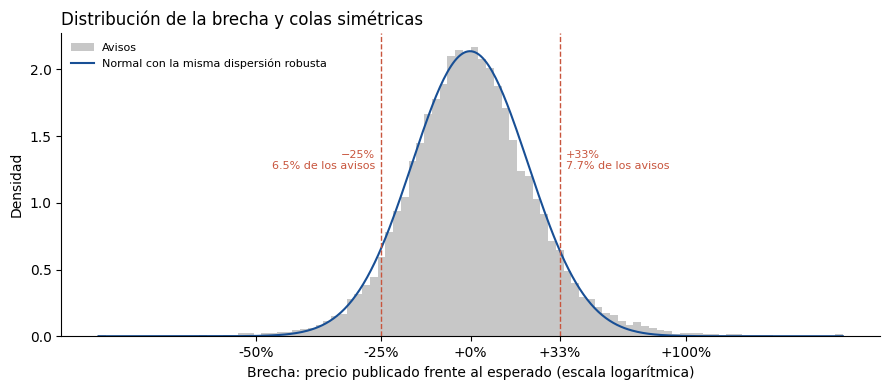

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
bordes = np.linspace(-1.2, 1.2, 97)
ax.hist(df["residuo"].clip(-1.2, 1.2), bins=bordes, density=True, color=GRIS, alpha=0.7, label="Avisos")
x = np.linspace(-1.2, 1.2, 400)
ax.plot(x, stats.norm.pdf(x, centro, mad), color=AZUL_OSCURO, lw=1.5, label="Normal con la misma dispersión robusta")
ax.axvline(umbral_log, color=ROJO, lw=1, ls="--")
ax.axvline(-umbral_log, color=ROJO, lw=1, ls="--")
ax.text(umbral_log - 0.02, ax.get_ylim()[1] * 0.55, f"−25%\n{100 * abajo.mean():.1f}% de los avisos", ha="right",
        fontsize=8, color=ROJO)
ax.text(-umbral_log + 0.02, ax.get_ylim()[1] * 0.55, f"+33%\n{100 * arriba.mean():.1f}% de los avisos", ha="left",
        fontsize=8, color=ROJO)
marcas_x = [-0.5, -0.25, 0, 1 / 3, 1]   # simétricas en log
ax.set_xticks(np.log1p(marcas_x), [f"{100 * m:+.0f}%" for m in marcas_x])
ax.set_xlabel("Brecha: precio publicado frente al esperado (escala logarítmica)")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de la brecha y colas simétricas", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

In [5]:
filas = []
for modelo_nombre, columna in [("lineal ampliado (oficial)", "residuo"), ("gradient boosting", "residuo_gbm")]:
    r = df[columna]
    centro_m, mad_m = r.median(), stats.median_abs_deviation(r, scale="normal")
    for umbral in [-0.20, -0.25, -0.30]:
        t = np.log(1 + umbral)
        for grupo, sel in [("todos", pd.Series(True, index=df.index))] + [
                (str(g), df["tercil_barrio"] == g) for g in df["tercil_barrio"].cat.categories]:
            filas.append({"modelo": modelo_nombre, "umbral": f"{100 * umbral:.0f}%", "grupo": grupo,
                          "abajo_%": 100 * (r[sel] < t).mean(), "arriba_%": 100 * (r[sel] > -t).mean(),
                          "esperado_normal_%": 100 * stats.norm.cdf(t, centro_m, mad_m)})
robustez_h1a = pd.DataFrame(filas)
robustez_h1a["abajo_menos_arriba_pp"] = robustez_h1a["abajo_%"] - robustez_h1a["arriba_%"]
robustez_h1a["exceso_sobre_normal_pp"] = robustez_h1a["abajo_%"] - robustez_h1a["esperado_normal_%"]
robustez_h1a.set_index(["modelo", "umbral", "grupo"]).round(2)

abajo_%  arriba_%  \
modelo                    umbral grupo                                
lineal ampliado (oficial) -20%   todos              11.80     12.78   
                                 barrios baratos    12.58     12.67   
                                 medios             11.64     12.73   
                                 caros              11.00     12.97   
                          -25%   todos               6.53      7.72   
                                 barrios baratos     7.53      7.46   
                                 medios              6.17      7.58   
                                 caros               5.65      8.20   
                          -30%   todos               3.53      4.47   
                                 barrios baratos     4.31      4.08   
                                 medios              3.35      4.38   
                                 caros               2.75      5.05   
gradient boosting         -20%   todos               9.69     10.96   
                                 barrios baratos    10.55     11.09   
                                 medios              9.71     11.04   
                                 caros               8.60     10.71   
                          -25%   todos               5.28      6.20   
                                 barrios baratos     6.02      6.46   
                                 medios              4.98      6.20   
                                 caros               4.68      5.87   
                          -30%   todos               2.62      3.49   
                                 barrios baratos     3.16      3.55   
                                 medios              2.55      3.59   
                                 caros               2.02      3.30   

                                                  esperado_normal_%  \
modelo                    umbral grupo                                
lineal ampliado (oficial) -20%   todos                        11.83   
                                 barrios baratos              11.83   
                                 medios                       11.83   
                                 caros                        11.83   
                          -25%   todos                         6.31   
                                 barrios baratos               6.31   
                                 medios                        6.31   
                                 caros                         6.31   
                          -30%   todos                         2.88   
                                 barrios baratos               2.88   
                                 medios                        2.88   
                                 caros                         2.88   
gradient boosting         -20%   todos                         9.22   
                                 barrios baratos               9.22   
                                 medios                        9.22   
                                 caros                         9.22   
                          -25%   todos                         4.34   
                                 barrios baratos               4.34   
                                 medios                        4.34   
                                 caros                         4.34   
                          -30%   todos                         1.68   
                                 barrios baratos               1.68   
                                 medios                        1.68   
                                 caros                         1.68   

                                                  abajo_menos_arriba_pp  \
modelo                    umbral grupo                                    
lineal ampliado (oficial) -20%   todos                            -0.98   
                                 barrios baratos                  -0.09   
                                 medios                 

> **Interpretación:** _(a completar)_

### 2.2 H1b: ¿los avisos marcados salen más del portal?

**Dato.** El primer relevamiento es del 14/08/2026 y el segundo, del 27 y 28/10/2026: pasaron **unos dos meses y
medio**. Para cada aviso del primero se registró si en el segundo seguía publicado, si se había republicado (otra
publicación con la misma dirección, m² y ambientes) o si ya no estaba.

**Cuidado: salir del portal no es lo mismo que venderse.** Un aviso puede salir porque se vendió, porque el dueño lo
retiró o porque se republicó y no lo detectamos. Si la brecha capta precios bajos, se espera que esos avisos salgan
más, pero salir no confirma la venta ni el precio.

**Población.** Se excluyen los barrios truncados por el tope de 2.016 resultados del primer relevamiento (Palermo,
Belgrano, Caballito y Recoleta): ahí no se vieron todos los avisos y la salida no es comparable. Las republicaciones
cuentan como "no salió" (siguen en venta); su exclusión va como robustez.

**Especificación.** Modelo de probabilidad lineal (el coeficiente se lee en puntos porcentuales) con efectos fijos de
barrio, controlando el log del valor esperado del departamento, el log de m² y si el aviso ya había bajado de precio
antes del primer relevamiento. Errores agrupados por unidad. Logit con su odds ratio como respaldo.

**Por qué no se controla por el precio publicado.** La brecha está hecha del precio publicado: controlar por él
compara avisos con la misma brecha "de otra forma" y borra el efecto. El comparable correcto es el valor esperado (lo
que el departamento debería valer). Se muestra en la robustez.

In [6]:
dias = (pd.Timestamp("2026-10-27") - pd.Timestamp(CFG["permisos_obra"]["fecha_scraping"])).days
print(f"Días entre relevamientos: {dias} (unos {dias / 30.4:.1f} meses)")
h1b = df.assign(salio=seguimiento["salio"].astype(int), estado=seguimiento["estado"],
                truncado=seguimiento["barrio_truncado"], marcado_int=df["marcado"].astype(int),
                log_valor_esperado=np.log(df["precio_m2_esperado"] * df["m2_final"]),
                log_m2=np.log(df["m2_final"]), bajo_antes=df["bajo_de_precio"].astype(int))
h1b = h1b[~h1b["truncado"]].copy()
print(f"Avisos fuera de los barrios truncados: {len(h1b):,} | republicados: {(h1b['estado'] == 'republicado').mean():.1%}")

tasas = {}
for nombre, sel in [("marcados", h1b["marcado"]), ("no marcados", ~h1b["marcado"])]:
    tasas[nombre] = inferencia.bootstrap_estadistico(h1b.loc[sel, "salio"], h1b.loc[sel, "unidad_cv"], b=500,
                                                     semilla=SEMILLA)
# Diferencia de tasas sin controles, con errores agrupados por unidad
sin_controles = smf.ols("salio ~ marcado_int", h1b).fit(cov_type="cluster", cov_kwds={"groups": h1b["unidad_cv"]})
dif_marca = inferencia.tabla_coeficientes(sin_controles, ["marcado_int"], "pp").iloc[0, :3].values / 100
tabla = pd.crosstab(h1b["marcado"], h1b["salio"])
chi2, p_chi, _, _ = stats.chi2_contingency(tabla)
pruebas_h1.append(inferencia.fila_prueba(
    "χ² de independencia (marcado × salida)", "salir del portal es independiente de estar marcado",
    "no es independiente", "χ²", chi2, p_chi))
pd.DataFrame({k: {"tasa_salida_%": 100 * v[0], "ic_inf_%": 100 * v[1], "ic_sup_%": 100 * v[2]}
              for k, v in {**tasas, "diferencia (pp)": dif_marca}.items()}).T.round(1)

Días entre relevamientos: 74 (unos 2.4 meses)


Avisos fuera de los barrios truncados: 19,579 | republicados: 23.8%


,tasa_salida_%,ic_inf_%,ic_sup_%
marcados,46.8,43.8,49.2
no marcados,39.7,39.0,40.5
diferencia (pp),7.0,4.1,9.9


In [7]:
controles = " + log_valor_esperado + log_m2 + bajo_antes + C(barrio)"
agrupado = {"cov_type": "cluster", "cov_kwds": {"groups": h1b["unidad_cv"]}}
lpm = smf.ols("salio ~ marcado_int" + controles, h1b).fit(**agrupado)
logit = smf.logit("salio ~ marcado_int" + controles, h1b).fit(disp=0, **agrupado)
efecto_lpm = inferencia.tabla_coeficientes(lpm, ["marcado_int"], "pp")
efecto_logit = inferencia.tabla_coeficientes(logit, ["marcado_int"], "or")
pruebas_h1.append(inferencia.fila_prueba(
    "Wald (probabilidad lineal, efectos fijos de barrio)", "estar marcado no cambia la probabilidad de salir",
    "la cambia", "z", lpm.tvalues["marcado_int"], lpm.pvalues["marcado_int"]))
pruebas_h1.append(inferencia.fila_prueba(
    "Wald (logit, efectos fijos de barrio)", "odds ratio = 1", "odds ratio ≠ 1", "z",
    logit.tvalues["marcado_int"], logit.pvalues["marcado_int"]))
pd.concat({"probabilidad lineal (pp)": efecto_lpm, "logit (odds ratio)": efecto_logit}).round(3)

,,efecto,ic_inf,ic_sup,p_valor
probabilidad lineal (pp),marcado_int,9.385,6.490,12.279,0.0
logit (odds ratio),marcado_int,1.484,1.317,1.671,0.0


**Gradiente.** Si la brecha capta precios bajos, la salida tendría que crecer de forma gradual a medida que el
aviso está más por debajo del esperado, no solo al cruzar el −25%. La especificación principal usa la brecha en log
con **dos pendientes**, una para la parte negativa y otra para la positiva, porque el efecto no tiene por qué ser
igual de los dos lados. Otras definiciones van en la robustez.

,efecto,ic_inf,ic_sup,p_valor
debajo_10pp,2.19,1.55,2.83,0.0
encima_10pp,-1.95,-2.55,-1.35,0.0


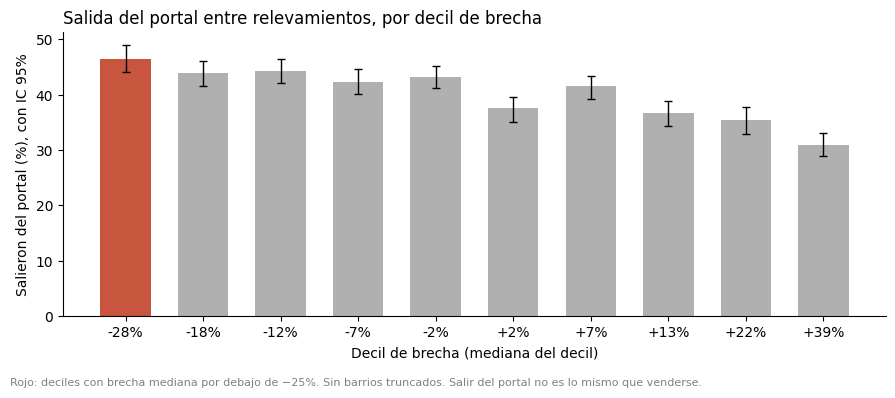

In [8]:
h1b["debajo_10pp"] = -h1b["residuo"].clip(upper=0) * 10    # cada unidad: 10 pp (en log) por debajo del esperado
h1b["encima_10pp"] = h1b["residuo"].clip(lower=0) * 10
gradiente = smf.ols("salio ~ debajo_10pp + encima_10pp" + controles, h1b).fit(**agrupado)
display(inferencia.tabla_coeficientes(gradiente, ["debajo_10pp", "encima_10pp"], "pp").round(2))
pruebas_h1.append(inferencia.fila_prueba(
    "Wald (pendiente de la brecha negativa)", "la salida no cambia con la brecha negativa", "cambia", "z",
    gradiente.tvalues["debajo_10pp"], gradiente.pvalues["debajo_10pp"]))
rho = stats.spearmanr(h1b["brecha"], h1b["salio"])
pruebas_h1.append(inferencia.fila_prueba(
    "Correlación de Spearman (brecha y salida)", "ρ = 0", "ρ ≠ 0", "ρ", rho.statistic, rho.pvalue))

h1b["decil"] = pd.qcut(h1b["brecha"], 10)
por_decil = h1b.groupby("decil", observed=True).apply(
    lambda g: pd.Series(dict(zip(["tasa", "inf", "sup"], inferencia.bootstrap_estadistico(
        g["salio"], g["unidad_cv"], b=300, semilla=SEMILLA))) | {"brecha_mediana": g["brecha"].median()}),
    include_groups=False)
fig, ax = plt.subplots(figsize=(9, 3.8))
pos = np.arange(len(por_decil))
ax.bar(pos, 100 * por_decil["tasa"], color=[ROJO if b < CFG["analisis"]["umbral"] else GRIS
                                           for b in por_decil["brecha_mediana"]], width=0.65)
ax.errorbar(pos, 100 * por_decil["tasa"], yerr=[100 * (por_decil["tasa"] - por_decil["inf"]),
                                                100 * (por_decil["sup"] - por_decil["tasa"])],
            fmt="none", color="black", lw=1, capsize=3)
ax.set_xticks(pos, [f"{100 * b:+.0f}%" for b in por_decil["brecha_mediana"]])
ax.set_xlabel("Decil de brecha (mediana del decil)")
ax.set_ylabel("Salieron del portal (%), con IC 95%")
ax.set_title("Salida del portal entre relevamientos, por decil de brecha", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.figtext(0.01, -0.03, "Rojo: deciles con brecha mediana por debajo de −25%. Sin barrios truncados. Salir del "
            "portal no es lo mismo que venderse.", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

In [9]:
def efecto_marca(datos, marca="marcado_int", formula_controles=controles):
    res = smf.ols(f"salio ~ {marca}" + formula_controles, datos).fit(
        cov_type="cluster", cov_kwds={"groups": datos["unidad_cv"]})
    return inferencia.tabla_coeficientes(res, [marca], "pp").iloc[0]


h1b["marcado_gbm"] = h1b["marcado_otro_modelo"].astype(int)
h1b["marcado_consenso_int"] = h1b["marcado_consenso"].astype(int)
h1b["caro"] = (h1b["residuo"] > -umbral_log).astype(int)
h1b["log_precio_publicado"] = np.log(h1b["precio_usd"])
filas = {
    "principal": efecto_marca(h1b),
    "sin republicados": efecto_marca(h1b[h1b["estado"] != "republicado"]),
    "marca del gradient boosting": efecto_marca(h1b, "marcado_gbm"),
    "marca de consenso (los dos modelos)": efecto_marca(h1b, "marcado_consenso_int"),
}
for tercil in h1b["tercil_barrio"].cat.categories:
    filas[f"solo {tercil}"] = efecto_marca(h1b[h1b["tercil_barrio"] == tercil])
filas["placebo: brecha > +33% (caros)"] = efecto_marca(h1b, "caro")
filas["control incorrecto: precio publicado"] = efecto_marca(
    h1b, formula_controles=" + log_precio_publicado + log_m2 + bajo_antes + C(barrio)")
pd.DataFrame(filas).T.round(2)

,efecto,ic_inf,ic_sup,p_valor
principal,9.38,6.49,12.28,0.00
sin republicados,7.55,4.37,10.72,0.00
marca del gradient boosting,10.25,7.10,13.40,0.00
marca de consenso (los dos modelos),10.96,7.38,14.53,0.00
solo barrios baratos,11.65,7.80,15.50,0.00
solo medios,4.99,-0.72,10.69,0.09
solo caros,9.29,2.46,16.12,0.01
placebo: brecha > +33% (caros),-8.40,-10.99,-5.80,0.00
control incorrecto: precio publicado,1.50,-1.66,4.67,0.35


In [10]:
# El mismo gradiente con otras definiciones de la brecha: con una sola pendiente para los dos lados, y recortando
# los extremos
definiciones = {
    "principal: log, pendiente de la parte negativa": None,
    "log, una pendiente": -h1b["residuo"] * 10,
    "brecha en %, una pendiente": -h1b["brecha"] * 10,
    "brecha en %, recortada a ±50%": -h1b["brecha"].clip(-0.5, 0.5) * 10,
}
filas = {}
for nombre, x in definiciones.items():
    if x is None:
        filas[nombre] = inferencia.tabla_coeficientes(gradiente, ["debajo_10pp"], "pp").iloc[0]
        continue
    res = smf.ols("salio ~ x" + controles, h1b.assign(x=x)).fit(**agrupado)
    filas[nombre] = inferencia.tabla_coeficientes(res, ["x"], "pp").iloc[0]
pd.DataFrame(filas).T.rename(columns={"efecto": "pp de salida cada 10 pp más por debajo"}).round(2)

,pp de salida cada 10 pp más por debajo,ic_inf,ic_sup,p_valor
"principal: log, pendiente de la parte negativa",2.19,1.55,2.83,0.0
"log, una pendiente",2.07,1.73,2.41,0.0
"brecha en %, una pendiente",1.59,1.15,2.03,0.0
"brecha en %, recortada a ±50%",2.26,1.90,2.62,0.0


> **Interpretación:** _(a completar)_

### 2.3 Resumen de los tests formales de H1

In [11]:
resumen_h1 = pd.DataFrame(pruebas_h1)
resumen_h1["p_holm"] = inferencia.holm(resumen_h1["p_valor"]).values
resumen_h1.assign(valor=resumen_h1["valor"].map(
    lambda v: f"{v:.3f}" if abs(v) < 1000 else f"{v:,.0f}"), p_valor=resumen_h1["p_valor"].map("{:.1e}".format),
                  p_holm=resumen_h1["p_holm"].map("{:.1e}".format))

,prueba,H0,H1,estadístico,valor,p_valor,decisión,p_holm
0,Binomial exacta unilateral (colas),P(brecha < −25%) ≤ P(brecha > +33%),la cola de abajo tiene más masa,proporción en la cola de abajo,0.458,1.0e+00,No se rechaza H0,1.0e+00
1,Kolmogorov-Smirnov contra la normal,el residuo estandarizado es normal,no es normal,D,0.018,1.6e-08,Se rechaza H0,4.8e-08
2,Shapiro-Wilk (muestra de 5.000),el residuo es normal,no es normal,W,0.971,8.8e-31,Se rechaza H0,6.2e-30
3,χ² de independencia (marcado × salida),salir del portal es independiente de estar mar...,no es independiente,χ²,25.619,4.2e-07,Se rechaza H0,8.3e-07
4,"Wald (probabilidad lineal, efectos fijos de ba...",estar marcado no cambia la probabilidad de salir,la cambia,z,6.354,2.1e-10,Se rechaza H0,8.4e-10
5,"Wald (logit, efectos fijos de barrio)",odds ratio = 1,odds ratio ≠ 1,z,6.482,9.0e-11,Se rechaza H0,4.5e-10
6,Wald (pendiente de la brecha negativa),la salida no cambia con la brecha negativa,cambia,z,6.728,1.7e-11,Se rechaza H0,1.0e-10
7,Correlación de Spearman (brecha y salida),ρ = 0,ρ ≠ 0,ρ,-0.089,1.8e-35,Se rechaza H0,1.4e-34


### 2.4 Resultado de H1: un resultado doble

- **H1a no se sostiene.** La brecha no prueba que haya más precios bajos de los que explica el error del modelo: la
  cola de abajo es más liviana que la de arriba (y no más pesada), y su masa no se aparta de la de una normal con la
  misma dispersión. El resultado se repite con otros umbrales, con el gradient boosting y en los tres terciles de
  barrio.
- **H1b sí se sostiene.** La brecha predice la salida del portal en los dos meses y medio siguientes: los avisos
  marcados salen más, dentro del mismo barrio y a igual valor esperado, con un gradiente (cuanto más por debajo, más
  salen) y con el placebo a favor (los avisos caros salen menos). Se mantiene sin las republicaciones y con la marca
  del gradient boosting o la de consenso. **En el tercil de barrios medios el IC incluye el 0**: ahí la evidencia es
  más débil.
- **Qué significa para el fondo.** La brecha no alcanza para afirmar que un aviso está subvaluado, pero sí ordena:
  los avisos marcados se comportan distinto en el mercado. Por eso la lista es de **señales a investigar**, no de
  oportunidades confirmadas, y salir del portal no prueba una venta.

> **Interpretación:** _(a completar)_

## 3. H2: la sub-zona da una referencia de precio más precisa que el barrio

> Un barrio no es homogéneo: la mediana de la sub-zona (k-means geográfico dentro del barrio) predice el precio por
> m² de un aviso mejor que la mediana del barrio.

**Población.** Avisos con coordenadas y sin geocodificación dudosa (las sub-zonas se recalculan sin ellos, como en la
etapa 6), en los barrios con al menos dos sub-zonas: en un barrio con una sola, sub-zona y barrio son lo mismo y no
hay nada que comparar.

**Medida.** Para cada aviso, el error porcentual absoluto de usar como referencia la mediana de su barrio y la de su
sub-zona, calculadas **sin ese aviso** (validación cruzada de 5 partes armadas por unidad, para que un duplicado no
quede de los dos lados). La diferencia pareada (error del barrio − error de la sub-zona) es positiva cuando la
sub-zona es mejor.

**Tests.** Como los avisos de una misma unidad no son independientes, la diferencia se promedia por unidad antes de
testear. t de una muestra (visto en clase) y Wilcoxon de rangos con signo (sin suponer normalidad), los dos
unilaterales: H2 afirma que la sub-zona es **mejor**. Por barrio, Wilcoxon bilateral (puede mejorar o empeorar) con
corrección de Holm por los 41 barrios.

**Robustez.** Otras semillas para las partes; el cruce con la estabilidad de las sub-zonas del notebook 04 (ARI); y la
misma pregunta dentro del modelo de precio: el lineal ampliado con la elección de sub-zonas de la etapa 6 contra el
mismo modelo comparando siempre contra el barrio.

In [12]:
from src import analisis, eda, validacion

pruebas_h2 = []
df_geo = analisis.tratar_geo_dudoso(analisis.unir_fuentes_externas(limpio, CFG["rutas"]), CFG["enriquecimiento"])
subzonas_por_barrio = df_geo.groupby("barrio")["subzona"].nunique()
h2 = df_geo[df_geo["subzona"].notna() & df_geo["barrio"].map(subzonas_por_barrio).ge(2)].copy()
h2["unidad_cv"] = modelo.grupo_de_unidad(h2)
args_error = dict(k=CFG["analisis"]["k_folds"], minimo_grupo=CFG["analisis"]["minimo_grupo"], unidad=h2["unidad_cv"])
h2["error_barrio"] = eda.error_vara_fuera_de_muestra(h2["precio_m2_usd"], h2["barrio"], semilla=SEMILLA, **args_error)
h2["error_subzona"] = eda.error_vara_fuera_de_muestra(h2["precio_m2_usd"], h2["subzona"], semilla=SEMILLA,
                                                      **args_error)
h2 = h2[h2["error_barrio"].notna() & h2["error_subzona"].notna()]
h2["diferencia"] = h2["error_barrio"] - h2["error_subzona"]
print(f"Avisos: {len(h2):,} | unidades: {h2['unidad_cv'].nunique():,} | barrios: {h2['barrio'].nunique()} | "
      f"sub-zonas: {h2['subzona'].nunique()}")
dif, inf, sup = inferencia.bootstrap_diferencia_medianas(h2["error_barrio"], h2["error_subzona"], h2["unidad_cv"],
                                                         semilla=SEMILLA)
print(f"Error mediano con el barrio: {100 * h2['error_barrio'].median():.2f}% | con la sub-zona: "
      f"{100 * h2['error_subzona'].median():.2f}%")
print(f"Diferencia: {100 * dif:.2f} pp (IC {100 * inf:.2f} a {100 * sup:.2f})")

/Users/gonzalobuhler/Documents/Facultad (ITBA)/2026 - 2C/Descriptiva/tp1-fondo-inmobiliario/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Definiendo sub-zonas por clustering...


  Sub-zonas creadas: 196 en total.
Avisos: 22,187 | unidades: 19,547 | barrios: 41 | sub-zonas: 189


Error mediano con el barrio: 17.70% | con la sub-zona: 17.10%
Diferencia: 0.59 pp (IC 0.40 a 0.80)


In [13]:
por_unidad = h2.groupby("unidad_cv")["diferencia"].mean()
t = stats.ttest_1samp(por_unidad, 0, alternative="greater")
w = stats.wilcoxon(por_unidad, alternative="greater")
pruebas_h2 += [
    inferencia.fila_prueba("t de una muestra (diferencia media por unidad)", "la sub-zona no reduce el error (μ ≤ 0)",
                           "la sub-zona reduce el error (μ > 0)", "t", t.statistic, t.pvalue),
    inferencia.fila_prueba("Wilcoxon de rangos con signo (por unidad)", "la diferencia no está corrida hacia arriba",
                           "la sub-zona reduce el error", "W", w.statistic, w.pvalue),
]
print(f"Diferencia media por unidad: {100 * por_unidad.mean():.2f} pp | t = {t.statistic:.2f} (p = {t.pvalue:.1e}) | "
      f"Wilcoxon p = {w.pvalue:.1e}")

Diferencia media por unidad: 0.97 pp | t = 14.40 (p = 4.7e-47) | Wilcoxon p = 1.7e-28


### 3.1 Barrio por barrio

In [14]:
filas = []
for barrio, g in h2.groupby("barrio"):
    d_unidad = g.groupby("unidad_cv")["diferencia"].mean()
    media, inf_b, sup_b = inferencia.bootstrap_estadistico(g["diferencia"], g["unidad_cv"], b=300, semilla=SEMILLA)
    filas.append({"barrio": barrio, "avisos": len(g), "error_barrio_%": 100 * g["error_barrio"].median(),
                  "error_subzona_%": 100 * g["error_subzona"].median(), "diferencia_media_pp": 100 * media,
                  "ic_inf_pp": 100 * inf_b, "ic_sup_pp": 100 * sup_b, "mediana_por_unidad_pp": 100 * d_unidad.median(),
                  "p_wilcoxon": stats.wilcoxon(d_unidad).pvalue})
por_barrio = pd.DataFrame(filas).set_index("barrio")
por_barrio["p_holm"] = inferencia.holm(por_barrio["p_wilcoxon"])
por_barrio["veredicto"] = np.where(por_barrio["p_holm"] >= 0.05, "sin diferencia",
                                   np.where(por_barrio["mediana_por_unidad_pp"] > 0, "mejora", "empeora"))
print(por_barrio["veredicto"].value_counts().to_string())
por_barrio.sort_values("diferencia_media_pp", ascending=False).round(2)

veredicto
sin diferencia    35
mejora             6


,avisos,error_barrio_%,error_subzona_%,diferencia_media_pp,ic_inf_pp,ic_sup_pp,mediana_por_unidad_pp,p_wilcoxon,p_holm,veredicto
barrio,,,,,,,,,,
villa-lugano,260,24.54,14.38,17.51,12.47,21.58,7.70,0.00,0.00,mejora
villa-ortuzar,169,18.82,15.23,10.74,1.08,19.18,1.48,0.25,1.00,sin diferencia
liniers,272,22.12,19.45,3.74,1.83,5.70,3.35,0.00,0.01,mejora
velez-sarsfield,62,15.56,13.07,3.02,0.16,5.74,4.10,0.34,1.00,sin diferencia
chacarita,190,19.89,16.73,2.60,-0.03,5.59,1.02,0.05,1.00,sin diferencia
flores,1023,19.91,18.51,2.36,1.43,3.21,2.53,0.00,0.00,mejora
barracas,371,20.82,19.59,2.31,0.96,3.46,2.31,0.00,0.07,sin diferencia
mataderos,208,18.14,16.60,2.15,0.85,3.46,1.23,0.02,0.65,sin diferencia
recoleta,1656,16.99,16.27,1.73,1.19,2.33,2.06,0.00,0.05,mejora


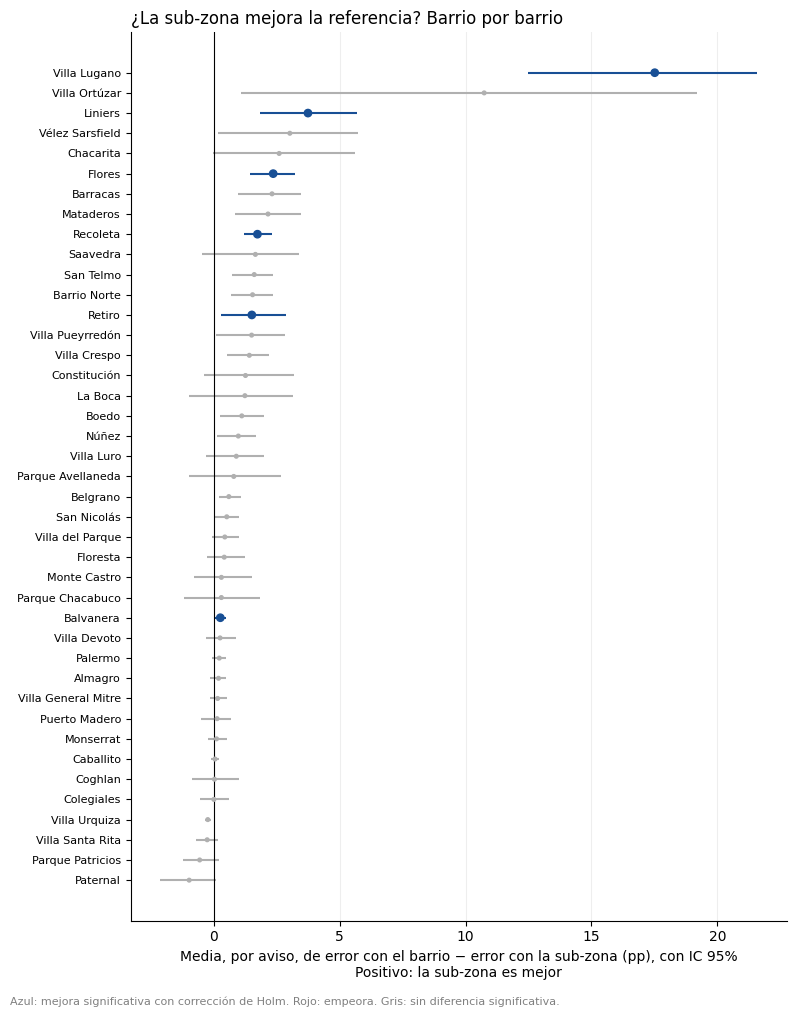

In [15]:
from src.eda import nombre_barrio

orden = por_barrio.sort_values("diferencia_media_pp")
colores = orden["veredicto"].map({"mejora": AZUL_OSCURO, "empeora": ROJO, "sin diferencia": GRIS})
marcadores = orden["veredicto"].map({"mejora": "o", "empeora": "s", "sin diferencia": "."})
fig, ax = plt.subplots(figsize=(8, 10))
pos = np.arange(len(orden))
ax.hlines(pos, orden["ic_inf_pp"], orden["ic_sup_pp"], color=colores, lw=1.5)
for m in ["o", "s", "."]:
    sel = (marcadores == m).values
    ax.scatter(orden["diferencia_media_pp"][sel], pos[sel], color=colores[sel], marker=m, s=28, zorder=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(pos, [nombre_barrio(b) for b in orden.index], fontsize=8)
ax.set_xlabel("Media, por aviso, de error con el barrio − error con la sub-zona (pp), con IC 95%\n"
              "Positivo: la sub-zona es mejor")
ax.set_title("¿La sub-zona mejora la referencia? Barrio por barrio", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.figtext(0.01, -0.01, "Azul: mejora significativa con corrección de Holm. Rojo: empeora. Gris: sin diferencia "
            "significativa.", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

> **Interpretación:** _(a completar)_

### 3.2 Robustez

In [16]:
filas = {}
for semilla in [SEMILLA, 7, 123]:
    eb = eda.error_vara_fuera_de_muestra(h2["precio_m2_usd"], h2["barrio"], semilla=semilla, **args_error)
    es = eda.error_vara_fuera_de_muestra(h2["precio_m2_usd"], h2["subzona"], semilla=semilla, **args_error)
    ok = eb.notna() & es.notna()
    filas[f"semilla {semilla}"] = {"error_barrio_%": 100 * eb[ok].median(), "error_subzona_%": 100 * es[ok].median(),
                                   "diferencia_pp": 100 * (eb[ok].median() - es[ok].median())}
pd.DataFrame(filas).T.round(2)

,error_barrio_%,error_subzona_%,diferencia_pp
semilla 42,17.72,17.15,0.57
semilla 7,17.67,17.09,0.58
semilla 123,17.72,17.07,0.65


In [17]:
# Estabilidad de las sub-zonas (como en el notebook 04): ¿mejoran más los barrios con sub-zonas estables?
estabilidad = validacion.estabilidad_subzonas(df_geo, repeticiones=CFG["analisis"]["repeticiones_estabilidad"])
cruce = por_barrio.join(estabilidad["ari_mediano"], how="left")
rho_ari = stats.spearmanr(cruce["diferencia_media_pp"], cruce["ari_mediano"], nan_policy="omit")
pruebas_h2.append(inferencia.fila_prueba(
    "Spearman (mejora del barrio y estabilidad ARI)", "ρ = 0", "ρ ≠ 0", "ρ", rho_ari.statistic, rho_ari.pvalue))
cruce["estable"] = np.where(cruce["ari_mediano"] >= CFG["analisis"]["ari_minimo_subzona"], "ARI ≥ 0,7", "ARI < 0,7")
print(f"Spearman entre la mejora y el ARI: {rho_ari.statistic:.2f} (p = {rho_ari.pvalue:.2f})")
pd.crosstab(cruce["veredicto"], cruce["estable"], margins=True, margins_name="total")

Spearman entre la mejora y el ARI: 0.02 (p = 0.91)


estable,"ARI ≥ 0,7",total
veredicto,,
mejora,6,6
sin diferencia,35,35
total,41,41


In [18]:
# Dentro del modelo de precio: la elección de sub-zonas de la etapa 6 contra comparar siempre con el barrio
y_geo = np.log(df_geo["precio_m2_usd"])
solo_barrio, _ = validacion.comparar_modelos(df_geo, y_geo, CFG["analisis"]["k_folds"], SEMILLA,
                                             CFG["analisis"]["minimo_grupo"], CFG["analisis"]["iqr_k"],
                                             modelos=["lineal_ampliado"],
                                             barrios_excluidos=list(df_geo["barrio"].unique()))
pred_oficial = np.log(etapa6["precio_m2_esperado"])
dif_m, inf_m, sup_m = validacion.bootstrap_diferencia_error(y_geo, solo_barrio["lineal_ampliado"], pred_oficial,
                                                            df["unidad_cv"], b=500)
print(f"Error mediano del lineal ampliado: con sub-zonas (etapa 6) "
      f"{100 * (np.exp(y_geo - pred_oficial) - 1).abs().median():.2f}% | siempre con el barrio "
      f"{100 * (np.exp(y_geo - solo_barrio['lineal_ampliado']) - 1).abs().median():.2f}%")
print(f"Diferencia (barrio − sub-zonas): {dif_m:.2f} pp (IC {inf_m:.2f} a {sup_m:.2f})")

Error mediano del lineal ampliado: con sub-zonas (etapa 6) 12.49% | siempre con el barrio 12.80%
Diferencia (barrio − sub-zonas): 0.31 pp (IC 0.19 a 0.44)


> **Interpretación:** _(a completar)_

### 3.3 Resumen de los tests formales de H2

In [19]:
resumen_h2 = pd.DataFrame(pruebas_h2)
resumen_h2["p_holm"] = inferencia.holm(resumen_h2["p_valor"]).values
print(f"Además, Wilcoxon por barrio con Holm: {(por_barrio['veredicto'] == 'mejora').sum()} de {len(por_barrio)} "
      f"mejoran, {(por_barrio['veredicto'] == 'empeora').sum()} empeoran.")
resumen_h2.assign(valor=resumen_h2["valor"].map(
    lambda v: f"{v:.3f}" if abs(v) < 1000 else f"{v:,.0f}"), p_valor=resumen_h2["p_valor"].map("{:.1e}".format),
                  p_holm=resumen_h2["p_holm"].map("{:.1e}".format))

Además, Wilcoxon por barrio con Holm: 6 de 41 mejoran, 0 empeoran.


,prueba,H0,H1,estadístico,valor,p_valor,decisión,p_holm
0,t de una muestra (diferencia media por unidad),la sub-zona no reduce el error (μ ≤ 0),la sub-zona reduce el error (μ > 0),t,14.397,4.7e-47,Se rechaza H0,1.4e-46
1,Wilcoxon de rangos con signo (por unidad),la diferencia no está corrida hacia arriba,la sub-zona reduce el error,W,"102,507,768",1.7e-28,Se rechaza H0,3.4e-28
2,Spearman (mejora del barrio y estabilidad ARI),ρ = 0,ρ ≠ 0,ρ,0.018,9.1e-01,No se rechaza H0,9.1e-01


> **Interpretación:** _(a completar)_

## 4. H3: la ubicación explica parte del precio dentro del barrio

> Parte de la diferencia de precio por m² dentro de un barrio se explica por la ubicación: cercanía al transporte
> (subte, tren, Metrobus, premetro) y entorno (espacios verdes, actividad de construcción, barrios populares,
> centralidad).

En la PreEntrega 2 solo había subte y centralidad, y no se detectó efecto; la devolución pidió completar el
transporte del sur y el oeste. Acá entran tren, Metrobus, premetro, espacios verdes y permisos de obra.

**Población.** Avisos con coordenadas y sin geocodificación dudosa.

**Modelo.** MCO del log del precio por m² sobre las características del lineal ampliado (con las expensas relativas
al barrio) y las variables de ubicación, con **efectos fijos de barrio**: cada efecto compara avisos del mismo
barrio. Las distancias van en tramos para leerlas en metros (menos de 300 m, 300 a 600, 600 a 1.000; base: más de
1.000 m). Espacio verde: menos de 300 m y 300 a 600 (base: más de 600 m). Premetro: solo un indicador de "a menos de
600 m", porque hay muy pocos avisos cerca (el IC va a ser ancho). Área verde a 500 m (por hectárea), permisos de obra
a 500 m (cada 10), barrio popular y distancia a los polos de centralidad (por km).

**Errores estándar agrupados por sub-zona** (principal). Las variables de ubicación son casi iguales entre vecinos:
los avisos de una misma sub-zona comparten el error de ubicación, y agrupar por unidad daría intervalos demasiado
angostos. Por unidad va como robustez.

**Tests.** Wald conjunto por bloque (transporte; entorno) y, por variable, corrección de Holm. Como respaldo de clase:
Kruskal-Wallis del residuo por tramo de distancia al subte y Spearman dentro del barrio entre cada distancia y el
residuo.

**Robustez.** Errores agrupados por unidad; efectos fijos de sub-zona en lugar de barrio; distancias continuas en log;
sur y oeste contra el resto; el premetro sin los avisos de barrios populares y su entorno, y si el bloque de
ubicación mejora la predicción fuera de muestra. **"Sur y oeste" es una elección del grupo:** las comunas 4 (La Boca,
Barracas, Parque Patricios, Nueva Pompeya), 8 (Villa Lugano, Villa Soldati, Villa Riachuelo), 9 (Liniers, Mataderos,
Parque Avellaneda) y 10 (Floresta, Vélez Sarsfield, Villa Luro, Monte Castro, Versalles, Villa Real), según el
GeoJSON oficial de barrios. Es la zona cuyo transporte (tren, Metrobus, premetro) faltaba en la PreEntrega 2.

**Límites.** Es una asociación dentro del barrio, no un efecto causal: estar cerca de una estación también es estar
sobre una avenida, con más ruido o más comercio. Las variables de ubicación están correlacionadas entre sí.

In [20]:
import statsmodels.api as sm

pruebas_h3 = []
h3 = df_geo[df_geo["lat"].notna()].copy()
y3 = np.log(h3["precio_m2_usd"])
caracteristicas = validacion.caracteristicas_ampliadas(h3)
log_exp = np.log(h3["expensas_usd"] / h3["m2_final"])
caracteristicas["expensas_rel_barrio"] = (log_exp - log_exp.groupby(h3["barrio"]).transform("median")).fillna(0)
caracteristicas["expensas_sin_dato"] = log_exp.isna().astype(float)


def tramos(distancia, nombre, cortes=(300, 600, 1000)):
    """Indicadores de tramo de distancia; el último tramo (el más lejano) queda como base."""
    etiquetas = ([f"{nombre}_menos_{cortes[0]}"] + [f"{nombre}_{a}_{b}" for a, b in zip(cortes[:-1], cortes[1:])]
                 + [f"{nombre}_mas_{cortes[-1]}"])
    return pd.get_dummies(pd.cut(distancia, [-1, *cortes, np.inf], labels=etiquetas), dtype=float).iloc[:, :-1]


transporte = pd.concat([tramos(h3["dist_transporte_m"], "subte"), tramos(h3["dist_tren_m"], "tren"),
                        tramos(h3["dist_metrobus_m"], "metrobus"),
                        (h3["dist_premetro_m"] < 600).astype(float).rename("premetro_menos_600")], axis=1)
entorno = pd.concat([tramos(h3["dist_espacio_verde_m"], "verde", (300, 600)), pd.DataFrame({
    "area_verde_ha": h3["area_verde_500m_ha"].clip(upper=h3["area_verde_500m_ha"].quantile(0.99)),
    "permisos_obra_10": h3["permisos_obra_500m"] / 10,
    "barrio_popular": h3["en_barrio_popular"].fillna(0),
    "centralidad_km": h3["dist_centralidad_m"] / 1000,
})], axis=1)
ubicacion = list(transporte.columns) + list(entorno.columns)
efectos_barrio = pd.get_dummies(h3["barrio"], prefix="barrio", drop_first=True, dtype=float)
X3 = sm.add_constant(pd.concat([caracteristicas, transporte, entorno, efectos_barrio], axis=1))
grupo_subzona = pd.factorize(h3["subzona"].fillna(h3["barrio"]))[0]
grupo_unidad = modelo.grupo_de_unidad(h3).values
principal = sm.OLS(y3, X3).fit(cov_type="cluster", cov_kwds={"groups": grupo_subzona})
print(f"Avisos: {len(h3):,} | sub-zonas (grupos): {len(set(grupo_subzona))} | R² = {principal.rsquared:.3f}")
coeficientes_h3 = inferencia.tabla_coeficientes(principal, ubicacion, "pct_log")
coeficientes_h3["p_holm"] = inferencia.holm(coeficientes_h3["p_valor"])
coeficientes_h3.round(3)

Avisos: 22,388 | sub-zonas (grupos): 196 | R² = 0.713


,efecto,ic_inf,ic_sup,p_valor,p_holm
subte_menos_300,-4.852,-8.808,-0.725,0.022,0.260
subte_300_600,-3.213,-6.954,0.678,0.104,1.000
subte_600_1000,-2.415,-5.750,1.037,0.168,1.000
tren_menos_300,-0.350,-3.542,2.948,0.833,1.000
tren_300_600,1.707,-1.140,4.636,0.243,1.000
tren_600_1000,1.972,-0.471,4.474,0.114,1.000
metrobus_menos_300,-2.306,-5.071,0.539,0.111,1.000
metrobus_300_600,-0.563,-3.723,2.701,0.732,1.000
metrobus_600_1000,1.385,-1.440,4.291,0.340,1.000
premetro_menos_600,-23.942,-34.722,-11.381,0.000,0.006


In [21]:
for bloque, variables in [("transporte", list(transporte.columns)), ("entorno", list(entorno.columns))]:
    wald = principal.wald_test(", ".join(f"{v} = 0" for v in variables), scalar=True)
    pruebas_h3.append(inferencia.fila_prueba(
        f"Wald conjunto: bloque de {bloque} (agrupado por sub-zona)", f"todos los coeficientes de {bloque} = 0",
        "al menos uno ≠ 0", "χ²", float(wald.statistic), float(wald.pvalue)))
    print(f"Bloque de {bloque}: χ² = {float(wald.statistic):.1f} con {len(variables)} restricciones, "
          f"p = {float(wald.pvalue):.1e}")
print(f"Variables significativas con Holm: {(coeficientes_h3['p_holm'] < 0.05).sum()} de {len(coeficientes_h3)}")

Bloque de transporte: χ² = 36.9 con 10 restricciones, p = 5.9e-05
Bloque de entorno: χ² = 41.9 con 6 restricciones, p = 1.9e-07
Variables significativas con Holm: 3 de 16


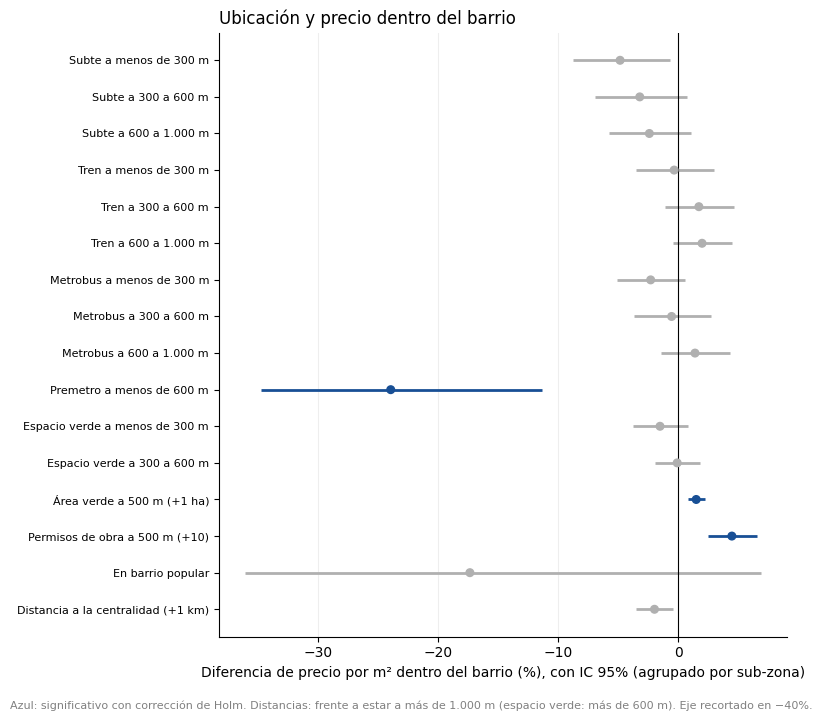

In [22]:
etiquetas_h3 = {
    "subte_menos_300": "Subte a menos de 300 m", "subte_300_600": "Subte a 300 a 600 m",
    "subte_600_1000": "Subte a 600 a 1.000 m", "tren_menos_300": "Tren a menos de 300 m",
    "tren_300_600": "Tren a 300 a 600 m", "tren_600_1000": "Tren a 600 a 1.000 m",
    "metrobus_menos_300": "Metrobus a menos de 300 m", "metrobus_300_600": "Metrobus a 300 a 600 m",
    "metrobus_600_1000": "Metrobus a 600 a 1.000 m", "premetro_menos_600": "Premetro a menos de 600 m",
    "verde_menos_300": "Espacio verde a menos de 300 m", "verde_300_600": "Espacio verde a 300 a 600 m",
    "area_verde_ha": "Área verde a 500 m (+1 ha)", "permisos_obra_10": "Permisos de obra a 500 m (+10)",
    "barrio_popular": "En barrio popular", "centralidad_km": "Distancia a la centralidad (+1 km)",
}
tabla = coeficientes_h3.iloc[::-1]
pos = np.arange(len(tabla))
color = np.where(tabla["p_holm"] < 0.05, AZUL_OSCURO, GRIS)
fig, ax = plt.subplots(figsize=(8, 7))
ax.hlines(pos, tabla["ic_inf"].clip(lower=-40), tabla["ic_sup"], color=color, lw=2)
ax.scatter(tabla["efecto"], pos, color=color, s=30, zorder=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(pos, [etiquetas_h3[v] for v in tabla.index], fontsize=8)
ax.set_xlabel("Diferencia de precio por m² dentro del barrio (%), con IC 95% (agrupado por sub-zona)")
ax.set_title("Ubicación y precio dentro del barrio", loc="left")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#eeeeee")
plt.figtext(0.01, -0.02, "Azul: significativo con corrección de Holm. Distancias: frente a estar a más de 1.000 m "
            "(espacio verde: más de 600 m). Eje recortado en −40%.", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

> **Interpretación:** _(a completar)_

### 4.1 Tests de clase como respaldo

El residuo es el del mismo modelo **sin** las variables de ubicación (características y efectos fijos de barrio): lo
que la ubicación tendría que explicar. Kruskal-Wallis compara el residuo entre tramos de distancia al subte sin
suponer normalidad; Spearman, la relación entre cada distancia y el residuo dentro del barrio. Ojo: estos dos tests suponen avisos independientes; como los
vecinos comparten la ubicación, sus p-valores son optimistas. Por eso la prueba principal es el Wald con errores
agrupados por sub-zona, y estos quedan como respaldo.

In [23]:
sin_ubicacion = sm.OLS(y3, sm.add_constant(pd.concat([caracteristicas, efectos_barrio], axis=1))).fit()
residuo_h3 = sin_ubicacion.resid
tramo_subte = pd.cut(h3["dist_transporte_m"], [-1, 300, 600, 1000, np.inf],
                     labels=["menos de 300 m", "300 a 600 m", "600 a 1.000 m", "más de 1.000 m"])
kw = stats.kruskal(*[residuo_h3[tramo_subte == t] for t in tramo_subte.cat.categories])
pruebas_h3.append(inferencia.fila_prueba(
    "Kruskal-Wallis (residuo por tramo de distancia al subte)", "el residuo tiene la misma distribución en los "
    "cuatro tramos", "al menos un tramo difiere", "H", kw.statistic, kw.pvalue))
display(residuo_h3.groupby(tramo_subte, observed=True).agg(["median", "size"]).rename(
    columns={"median": "residuo_mediano"}).round(4))
filas = {}
for nombre, columna in [("subte", "dist_transporte_m"), ("tren", "dist_tren_m"), ("Metrobus", "dist_metrobus_m"),
                        ("espacio verde", "dist_espacio_verde_m"), ("centralidad", "dist_centralidad_m")]:
    rho, p, n = eda.correlacion_intra_grupo(h3[columna], residuo_h3, h3["barrio"])
    filas[nombre] = {"rho_dentro_del_barrio": rho, "p_valor": p}
    pruebas_h3.append(inferencia.fila_prueba(
        f"Spearman dentro del barrio (distancia a {nombre} y residuo)", "ρ = 0", "ρ ≠ 0", "ρ", rho, p))
pd.DataFrame(filas).T.round(4)

,residuo_mediano,size
dist_transporte_m,,
menos de 300 m,-0.0136,6266
300 a 600 m,-0.0007,6718
600 a 1.000 m,0.0011,3801
más de 1.000 m,0.0010,5603


,rho_dentro_del_barrio,p_valor
subte,0.0252,0.0002
tren,-0.0034,0.6107
Metrobus,0.0138,0.0393
espacio verde,-0.0080,0.2329
centralidad,-0.0545,0.0000


> **Interpretación:** _(a completar)_

### 4.2 Robustez

In [24]:
def ajustar_ubicacion(X, grupos):
    return sm.OLS(y3, X).fit(cov_type="cluster", cov_kwds={"groups": grupos})


efectos_subzona = pd.get_dummies(h3["subzona"].fillna(h3["barrio"]), prefix="sz", drop_first=True, dtype=float)
especificaciones = {
    "principal (efectos de barrio, agrupado por sub-zona)": principal,
    "agrupado por unidad": ajustar_ubicacion(X3, grupo_unidad),
    "efectos fijos de sub-zona": ajustar_ubicacion(
        sm.add_constant(pd.concat([caracteristicas, transporte, entorno, efectos_subzona], axis=1)), grupo_subzona),
}
claves = ["subte_menos_300", "tren_menos_300", "metrobus_menos_300", "premetro_menos_600", "verde_menos_300",
          "area_verde_ha", "permisos_obra_10", "centralidad_km"]
robustez_h3 = pd.concat({nombre: inferencia.tabla_coeficientes(res, claves, "pct_log")[["efecto", "ic_inf", "ic_sup"]]
                         for nombre, res in especificaciones.items()}, axis=1)
robustez_h3.rename(index=etiquetas_h3).round(2)

principal (efectos de barrio, agrupado por sub-zona)  \
                                                                                 efecto   
Subte a menos de 300 m                                                          -4.85     
Tren a menos de 300 m                                                           -0.35     
Metrobus a menos de 300 m                                                       -2.31     
Premetro a menos de 600 m                                                      -23.94     
Espacio verde a menos de 300 m                                                  -1.53     
Área verde a 500 m (+1 ha)                                                       1.48     
Permisos de obra a 500 m (+10)                                                   4.45     
Distancia a la centralidad (+1 km)                                              -1.99     

                                                 agrupado por unidad         \
                                   ic_inf ic_sup              efecto ic_inf   
Subte a menos de 300 m              -8.81  -0.72               -4.85  -6.59   
Tren a menos de 300 m               -3.54   2.95               -0.35  -1.87   
Metrobus a menos de 300 m           -5.07   0.54               -2.31  -3.55   
Premetro a menos de 600 m          -34.72 -11.38              -23.94 -29.27   
Espacio verde a menos de 300 m      -3.79   0.79               -1.53  -2.73   
Área verde a 500 m (+1 ha)           0.79   2.18                1.48   1.21   
Permisos de obra a 500 m (+10)       2.43   6.52                4.45   3.62   
Distancia a la centralidad (+1 km)  -3.49  -0.46               -1.99  -2.51   

                                          efectos fijos de sub-zona         \
                                   ic_sup                    efecto ic_inf   
Subte a menos de 300 m              -3.09                     -8.44 -13.59   
Tren a menos de 300 m                1.19                     -2.92  -6.97   
Metrobus a menos de 300 m           -1.05                     -2.26  -5.15   
Premetro a menos de 600 m          -18.22                    -23.59 -35.72   
Espacio verde a menos de 300 m      -0.31                     -0.24  -2.82   
Área verde a 500 m (+1 ha)           1.76                      1.06   0.29   
Permisos de obra a 500 m (+10)       5.30                      2.79   0.39   
Distancia a la centralidad (+1 km)  -1.47                     -1.15  -3.55   

                                           
                                   ic_sup  
Subte a menos de 300 m              -2.99  
Tren a menos de 300 m                1.31  
Metrobus a menos de 300 m            0.71  
Premetro a menos de 600 m           -9.17  
Espacio verde a menos de 300 m       2.40  
Área verde a 500 m (+1 ha)           1.84  
Permisos de obra a 500 m (+10)       5.25  
Distancia a la centralidad (+1 km)   1.31

In [25]:
# Distancias continuas: cuánto cambia el precio si la distancia se duplica (en lugar de tramos)
continuas = pd.DataFrame({f"log2_{n}": np.log2(h3[c] + 50) for n, c in [
    ("subte", "dist_transporte_m"), ("tren", "dist_tren_m"), ("metrobus", "dist_metrobus_m"),
    ("premetro", "dist_premetro_m"), ("verde", "dist_espacio_verde_m")]})
X_log = sm.add_constant(pd.concat([caracteristicas, continuas, entorno.drop(columns=["verde_menos_300", "verde_300_600"]),
                                   efectos_barrio], axis=1))
con_log = ajustar_ubicacion(X_log, grupo_subzona)
tabla_log = inferencia.tabla_coeficientes(con_log, list(continuas.columns), "pct_log")
tabla_log["p_holm"] = inferencia.holm(tabla_log["p_valor"])
print("Diferencia de precio por m² (%) si la distancia se duplica:")
tabla_log.round(3)

Diferencia de precio por m² (%) si la distancia se duplica:


,efecto,ic_inf,ic_sup,p_valor,p_holm
log2_subte,1.520,0.279,2.776,0.016,0.065
log2_tren,-0.394,-1.838,1.072,0.597,0.597
log2_metrobus,0.840,-0.102,1.790,0.081,0.242
log2_premetro,8.336,2.355,14.666,0.006,0.029
log2_verde,0.610,-0.181,1.407,0.131,0.262


In [26]:
# Sur y oeste (comunas 4, 8, 9 y 10) contra el resto: el transporte de esas zonas es el que faltaba en la PE2
import json
import unicodedata


def normalizar(nombre):
    texto = unicodedata.normalize("NFKD", str(nombre)).encode("ascii", "ignore").decode().upper()
    return texto.replace("GRAL.", "GENERAL").replace(".", "").strip()


barrios_geo = json.load(open(RAIZ / CFG["fuentes_externas"]["rutas"]["barrios"], encoding="utf-8"))
comuna = {normalizar(f["properties"]["nombre"]): int(f["properties"]["comuna"]) for f in barrios_geo["features"]}
h3["comuna"] = h3["barrio_oficial"].map(normalizar).map(comuna)
sur_oeste = h3["comuna"].isin([4, 8, 9, 10]).values
print(f"Avisos sin comuna asignada: {h3['comuna'].isna().sum()} | en el sur y oeste: {sur_oeste.sum():,}")
por_zona = {}
for nombre, sel in [("sur y oeste", sur_oeste), ("resto", ~sur_oeste)]:
    Xs = X3[sel].loc[:, X3[sel].std() > 0].assign(const=1.0)
    res = sm.OLS(y3[sel], Xs).fit(cov_type="cluster", cov_kwds={"groups": grupo_subzona[sel]})
    presentes = [c for c in claves if c in res.params.index]
    por_zona[nombre] = inferencia.tabla_coeficientes(res, presentes, "pct_log")[["efecto", "ic_inf", "ic_sup"]]
pd.concat(por_zona, axis=1).rename(index=etiquetas_h3).round(2)

Avisos sin comuna asignada: 0 | en el sur y oeste: 2,517


sur y oeste                resto         \
                                        efecto ic_inf ic_sup efecto ic_inf   
Subte a menos de 300 m                    0.63 -13.83  17.53  -5.18  -9.10   
Tren a menos de 300 m                   -10.44 -19.85   0.07   0.26  -2.97   
Metrobus a menos de 300 m                 6.61  -0.94  14.74  -3.16  -5.95   
Premetro a menos de 600 m               -12.43 -25.04   2.29 -32.59 -35.86   
Espacio verde a menos de 300 m            6.74  -0.63  14.66  -2.08  -4.41   
Área verde a 500 m (+1 ha)               -1.58  -2.91  -0.24   2.01   1.45   
Permisos de obra a 500 m (+10)           11.97   5.44  18.90   4.24   2.31   
Distancia a la centralidad (+1 km)       -2.65  -6.23   1.06  -1.82  -3.38   

                                           
                                   ic_sup  
Subte a menos de 300 m              -1.10  
Tren a menos de 300 m                3.59  
Metrobus a menos de 300 m           -0.28  
Premetro a menos de 600 m          -29.15  
Espacio verde a menos de 300 m       0.30  
Área verde a 500 m (+1 ha)           2.56  
Permisos de obra a 500 m (+10)       6.22  
Distancia a la centralidad (+1 km)  -0.23

In [27]:
# Premetro: los avisos cerca del premetro están en el sur, junto a barrios populares. ¿Sobrevive el efecto sin ellos?
import geopandas as gpd

crs = CFG["fuentes_externas"]["crs_metrico"]
populares = gpd.read_file(RAIZ / CFG["fuentes_externas"]["rutas"]["barrios_populares"]).to_crs(crs)
puntos = gpd.GeoSeries(gpd.points_from_xy(h3["lon"], h3["lat"]), crs="EPSG:4326", index=h3.index).to_crs(crs)
h3["dist_barrio_popular_m"] = puntos.distance(populares.union_all())
cerca_premetro = transporte["premetro_menos_600"] == 1
print(f"Avisos a menos de 600 m del premetro: {cerca_premetro.sum()} | dentro de un barrio popular: "
      f"{int(h3.loc[cerca_premetro, 'en_barrio_popular'].fillna(0).sum())} | a menos de 500 m de uno: "
      f"{(h3.loc[cerca_premetro, 'dist_barrio_popular_m'] < 500).sum()}")
filas = {}
for nombre, sel in [("todos (principal)", np.ones(len(h3), dtype=bool)),
                    ("sin avisos dentro de barrios populares", (h3["en_barrio_popular"].fillna(0) == 0).values),
                    ("sin avisos a menos de 500 m de un barrio popular",
                     ((h3["en_barrio_popular"].fillna(0) == 0) & (h3["dist_barrio_popular_m"] >= 500)).values)]:
    Xs = X3[sel].loc[:, X3[sel].std() > 0].assign(const=1.0)
    res = sm.OLS(y3[sel], Xs).fit(cov_type="cluster", cov_kwds={"groups": grupo_subzona[sel]})
    fila = {"avisos": int(sel.sum()), "avisos_cerca_del_premetro": int(cerca_premetro[sel].sum())}
    if "premetro_menos_600" in res.params.index:
        fila.update(inferencia.tabla_coeficientes(res, ["premetro_menos_600"], "pct_log").iloc[0].to_dict())
    filas[nombre] = fila
pd.DataFrame(filas).T.round(2)

Avisos a menos de 600 m del premetro: 115 | dentro de un barrio popular: 38 | a menos de 500 m de uno: 106


,avisos,avisos_cerca_del_premetro,efecto,ic_inf,ic_sup,p_valor
todos (principal),22388.0,115.0,-23.94,-34.72,-11.38,0.00
sin avisos dentro de barrios populares,22296.0,77.0,-27.14,-36.44,-16.48,0.00
sin avisos a menos de 500 m de un barrio popular,18451.0,9.0,-4.24,-9.38,1.20,0.12


**Premetro: es la zona, no el premetro.** 106 de los 115 avisos a menos de 600 m del premetro están a menos de 500 m
de un barrio popular. Sacando esos avisos, el efecto pasa de −24% a −4% y su intervalo incluye el 0, aunque con solo 9
avisos cerca del premetro no se puede estimar con precisión. El −24% del modelo principal refleja el entorno (barrios
populares del sur), no la cercanía al premetro: no se puede separar una cosa de la otra con estos datos.

In [28]:
# ¿Predice mejor? Error fuera de muestra (5 vueltas por unidad) con y sin el bloque de ubicación
partes = modelo.folds_agrupados(pd.Series(grupo_unidad, index=h3.index), CFG["analisis"]["k_folds"], SEMILLA)
X_sin = sm.add_constant(pd.concat([caracteristicas, efectos_barrio], axis=1))
pred_con, pred_sin = pd.Series(np.nan, index=h3.index), pd.Series(np.nan, index=h3.index)
for p in sorted(partes.unique()):
    prueba = partes == p
    pred_con[prueba] = sm.OLS(y3[~prueba], X3[~prueba]).fit().predict(X3[prueba])
    pred_sin[prueba] = sm.OLS(y3[~prueba], X_sin[~prueba]).fit().predict(X_sin[prueba])
dif_pred = validacion.bootstrap_diferencia_error(y3, pred_con, pred_sin, pd.Series(grupo_unidad, index=h3.index), b=500)
print(f"Error mediano fuera de muestra: sin ubicación {100 * (np.exp(y3 - pred_sin) - 1).abs().median():.2f}% | "
      f"con ubicación {100 * (np.exp(y3 - pred_con) - 1).abs().median():.2f}%")
print(f"Diferencia (con − sin): {dif_pred[0]:.2f} pp (IC {dif_pred[1]:.2f} a {dif_pred[2]:.2f})")

Error mediano fuera de muestra: sin ubicación 12.69% | con ubicación 12.47%
Diferencia (con − sin): -0.21 pp (IC -0.36 a -0.08)


> **Interpretación:** _(a completar)_

### 4.3 Resumen de los tests formales de H3

In [29]:
resumen_h3 = pd.DataFrame(pruebas_h3)
resumen_h3["p_holm"] = inferencia.holm(resumen_h3["p_valor"]).values
resumen_h3.assign(valor=resumen_h3["valor"].map(lambda v: f"{v:.3f}" if abs(v) < 1000 else f"{v:,.0f}"),
                  p_valor=resumen_h3["p_valor"].map("{:.1e}".format),
                  p_holm=resumen_h3["p_holm"].map("{:.1e}".format))

,prueba,H0,H1,estadístico,valor,p_valor,decisión,p_holm
0,Wald conjunto: bloque de transporte (agrupado ...,todos los coeficientes de transporte = 0,al menos uno ≠ 0,χ²,36.895,5.9e-05,Se rechaza H0,3.0e-04
1,Wald conjunto: bloque de entorno (agrupado por...,todos los coeficientes de entorno = 0,al menos uno ≠ 0,χ²,41.884,1.9e-07,Se rechaza H0,1.4e-06
2,Kruskal-Wallis (residuo por tramo de distancia...,el residuo tiene la misma distribución en los ...,al menos un tramo difiere,H,29.965,1.4e-06,Se rechaza H0,8.4e-06
3,Spearman dentro del barrio (distancia a subte ...,ρ = 0,ρ ≠ 0,ρ,0.025,1.6e-04,Se rechaza H0,6.4e-04
4,Spearman dentro del barrio (distancia a tren y...,ρ = 0,ρ ≠ 0,ρ,-0.003,6.1e-01,No se rechaza H0,6.1e-01
5,Spearman dentro del barrio (distancia a Metrob...,ρ = 0,ρ ≠ 0,ρ,0.014,3.9e-02,Se rechaza H0,1.2e-01
6,Spearman dentro del barrio (distancia a espaci...,ρ = 0,ρ ≠ 0,ρ,-0.008,2.3e-01,No se rechaza H0,4.7e-01
7,Spearman dentro del barrio (distancia a centra...,ρ = 0,ρ ≠ 0,ρ,-0.055,3.2e-16,Se rechaza H0,2.6e-15


> **Interpretación:** _(a completar)_